# The Annotated Construct and Reducer Functions

### Set the OpenAI API Key as an Environment Variable

In [1]:
%load_ext dotenv
%dotenv
%load_ext mypy_ipython

### Import Relevant Classes and Functions

In [2]:
from langgraph.graph import START, END, StateGraph, add_messages
from typing_extensions import TypedDict
from langchain_openai.chat_models import ChatOpenAI
from langchain_core.messages import AIMessage, HumanMessage, BaseMessage
from collections.abc import Sequence
from typing import Literal, Annotated

### Get Familiar with the add_messages Function

In [3]:
my_list = add_messages([HumanMessage("Hi! I'm Oscar."), 
                        AIMessage("Hey, Oscar. How can I assist you?")],
                       [HumanMessage("Could you summarize today's news?")])

In [4]:
my_list

[HumanMessage(content="Hi! I'm Oscar.", additional_kwargs={}, response_metadata={}, id='33aa0770-7c0d-425e-8066-13758ef0ffd2'),
 AIMessage(content='Hey, Oscar. How can I assist you?', additional_kwargs={}, response_metadata={}, id='8b0c5d54-6fda-405c-b7c5-f82dbed5f2fe', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content="Could you summarize today's news?", additional_kwargs={}, response_metadata={}, id='20906288-147b-463b-8da7-ff0dc63834f8')]

### Define the State

In [5]:
class State(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]

### Define the Nodes

In [6]:
chat = ChatOpenAI(model = "gpt-4o", 
                  seed = 365, 
                  temperature = 0, 
                  max_completion_tokens = 100)

In [7]:
def ask_question(state: State) -> State:
    
    print(f"\n-------> ENTERING ask_question:")
    
    print("What is your question?")
    
    return State(messages = [HumanMessage(input())])

In [8]:
def chatbot(state: State) -> State:
    
    print(f"\n-------> ENTERING chatbot:")
    
    response = chat.invoke(state["messages"])
    response.pretty_print()
    
    return State(messages = [response])

In [9]:
def ask_another_question(state: State) -> State:
    
    print(f"\n-------> ENTERING ask_another_question:")
    
    print("Would you like to ask one more question (yes/no)?")
    
    return State(messages = [HumanMessage(input())])

### Define the Routing Function

In [10]:
def routing_function(state: State) -> Literal["ask_question", "__end__"]:
    
    if state["messages"][0].content == "yes":
        return "ask_question"
    else:
        return "__end__"

### Define the Graph

In [11]:
graph = StateGraph(State)

In [12]:
graph.add_node("ask_question", ask_question)
graph.add_node("chatbot", chatbot)
graph.add_node("ask_another_question", ask_another_question)

graph.add_edge(START, "ask_question")
graph.add_edge("ask_question", "chatbot")
graph.add_edge("chatbot", "ask_another_question")
graph.add_conditional_edges(source = "ask_another_question", 
                            path = routing_function)

In [13]:
graph_compiled = graph.compile()

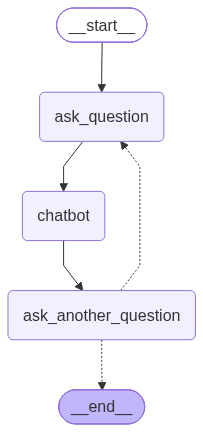

In [14]:
graph_compiled

### Test the Graph

In [15]:
graph_compiled.invoke(State(messages = []))


-------> ENTERING ask_question:
What is your question?

-------> ENTERING chatbot:
================================== Ai Message ==================================

The question "Who are we?" can be interpreted in various ways depending on the context. Here are a few possibilities:

1. **Philosophical Perspective**: From a philosophical standpoint, this question delves into the nature of human existence, identity, and consciousness. It invites exploration of what it means to be human, our purpose, and our place in the universe.

2. **Cultural or Societal Perspective**: In a cultural or societal context, "Who are we?"

-------> ENTERING ask_another_question:
Would you like to ask one more question (yes/no)?


{'messages': [HumanMessage(content='who are we?', additional_kwargs={}, response_metadata={}, id='176c05e6-1498-4f67-a804-990e53ac8a82'),
  AIMessage(content='The question "Who are we?" can be interpreted in various ways depending on the context. Here are a few possibilities:\n\n1. **Philosophical Perspective**: From a philosophical standpoint, this question delves into the nature of human existence, identity, and consciousness. It invites exploration of what it means to be human, our purpose, and our place in the universe.\n\n2. **Cultural or Societal Perspective**: In a cultural or societal context, "Who are we?"', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 100, 'prompt_tokens': 11, 'total_tokens': 111, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'c